## ChatBot with message summarization

### Goal

- Now, let's take it one step further!
- Rather than just trimming or filtering messages, we'll show how to use LLMs to produce a running summary of the conversation.
- This allows us to retain a compressed representation of the full conversation, rather than just removing it with trimming or filtering.
- We'll incorporate this summarization into a simple Chatbot.
- And we'll equip that Chatbot with memory, supporting long-running conversations without incurring high token cost / latency.


In [50]:
from langchain_ollama import ChatOllama




In [51]:
ollama = ChatOllama(model= "qwen2.5:7b")

In [52]:
from langgraph.graph import MessagesState

In addition to the built-in messages key, we'll now include a custom key (summary).

In [53]:
class State(MessagesState):
    summary: str

In [54]:
from langchain_core.messages import SystemMessage, HumanMessage, RemoveMessage

In [55]:
def call_model(state:State):

    # Get summary if exists

    summary = state.get("summary", "")

    if summary:
        # Add summary to system message
        system_message = f"Summary of conversation earlier: {summary}"
        # Append summary to any newer messages
        messages = [SystemMessage(content=system_message)] + state["messages"]
    
    else:
        messages = state["messages"]
    
    response = ollama.invoke(messages)

    return {
        "messages": response
    }
    




Note, here we'll use RemoveMessage to filter our state after we've produced the summary.

In [56]:
def summarize_conversation(state:State):
    summary = state.get("summary", "")

    if summary:
        # A summary already exists
        summary_message = (
            f"This is summary of the conversation to date: {summary}\n\n"
            "Extend the summary by taking into account the new messages above:"
        )
    
    else:
        summary_message = "Create a summary of the conversation above:"
    # Add prompt to our history
    messages = state["messages"] + [HumanMessage(content=summary_message)]
    response = ollama.invoke(messages)

    # Delete all but the 2 most recent messages
    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]

    return {"summary": response.content, "messages": delete_messages}







In [57]:

from langgraph.graph import END
from typing_extensions import Literal
# Determine whether to end or summarize the conversation
def should_continue(state: State) -> Literal ["summarize_conversation",END]:
    """Return the next node to execute."""
    messages = state["messages"]
    
    # If there are more than six messages, then we summarize the conversation
    if len(messages) > 6:
        return "summarize_conversation"
    
    # Otherwise we can just end
    return END

## Adding Memory

- Recall that state is transient to a single graph execution.
- This limits our ability to have multi-turn conversations with interruptions.
- As introduced at the end of Module 1, we can use [persistence](https://docs.langchain.com/oss/python/langgraph/persistence) to address this!
- LangGraph can use a checkpointer to automatically save the graph state after each step.
- This built-in persistence layer provides memory, allowing LangGraph to resume from the last state update.
- As we previously showed, one of the easiest to work with is MemorySaver, an in-memory key-value store for Graph state.
- All we need to do is compile the graph with a checkpointer, and our graph has memory!

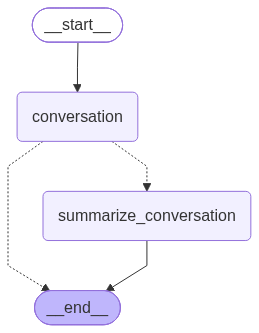

In [58]:
from IPython.display import Image, display
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START

# Define a new graph
workflow = StateGraph(State)
workflow.add_node("conversation", call_model)
workflow.add_node(summarize_conversation)

# Set the entrypoint as conversation
workflow.add_edge(START, "conversation")
workflow.add_conditional_edges("conversation", should_continue)
workflow.add_edge("summarize_conversation", END)


# Compile
memory = MemorySaver()
graph = workflow.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [59]:
# Create a thread
config = {"configurable": {"thread_id": "1"}}
input_message = HumanMessage(content="hi! I'm Bilal")
output = graph.invoke({"messages": [input_message]}, config) 
for m in output['messages'][-1:]:
    m.pretty_print()





================================== Ai Message ==================================

Hello Bilal! Nice to meet you. How can I assist you today? Is there anything specific you'd like to discuss or any questions you have?


In [60]:
input_message = HumanMessage(content="what's my name?")
output = graph.invoke({"messages": [input_message]}, config) 
for m in output['messages']:
    m.pretty_print()

================================ Human Message =================================

hi! I'm Bilal
================================== Ai Message ==================================

Hello Bilal! Nice to meet you. How can I assist you today? Is there anything specific you'd like to discuss or any questions you have?
================================ Human Message =================================

what's my name?
================================== Ai Message ==================================

Your name is Bilal.


Now, we don't yet have a summary of the state because we still have < = 6 messages.

In [61]:
graph.get_state(config).values.get("summary","")

''

In [62]:
input_message = HumanMessage(content="i like Ac Milan, give how many europe trphies it has?")
output = graph.invoke({"messages": [input_message]}, config) 
for m in output['messages']:
    m.pretty_print()

================================ Human Message =================================

hi! I'm Bilal
================================== Ai Message ==================================

Hello Bilal! Nice to meet you. How can I assist you today? Is there anything specific you'd like to discuss or any questions you have?
================================ Human Message =================================

what's my name?
================================== Ai Message ==================================

Your name is Bilal.
================================ Human Message =================================

i like Ac Milan, give how many europe trphies it has?
================================== Ai Message ==================================

AC Milan has won the UEFA Champions League (formerly known as the European Champions Cup) five times. Here are the years they won:

1. 1962–63
2. 1968–69
3. 1988–89
4. 1990–91
5. 2002–03

So, AC Milan has five European trophies from the UEFA Champions League. They have

In [63]:


graph.get_state(config).values.get("summary","")



''

In [64]:
input_message = HumanMessage(content="whar is the team that classical enemy yo AC Milan")
output = graph.invoke({"messages": [input_message]}, config) 
for m in output['messages'][:]:
    m.pretty_print()

================================ Human Message =================================

whar is the team that classical enemy yo AC Milan
================================== Ai Message ==================================

AC Milan's primary historic and rival team is Inter Milan. The two teams are often referred to as "Derby della Madonnina" or "Derby della Riviera" in Italian, meaning "Derby of the Madonna" and "Derby of the Coast," respectively. This rivalry is one of the most intense and longstanding in Italian football.

Other notable rivals of AC Milan include:

1. **Alessio Roma**: Known as the Derby del Capitello.
2. **Lazio**: Known as the Derby della Capitale.
3. **Juventus**: Known as the Derby d'Italia.

These rivalries have shaped the history and culture of Italian football.


In [65]:
graph.get_state(config).values.get("summary","")

'Sure! Here\'s a summary of our conversation:\n\n1. **Introduction**: You introduced yourself as Bilal.\n2. **Question about European Trophies**: You asked about how many European trophies AC Milan has won. AC Milan has won the UEFA Champions League (formerly known as the European Champions Cup) five times, in the seasons 1962–63, 1968–69, 1988–89, 1990–91, and 2002–03.\n3. **Question about Rival Team**: You asked about AC Milan\'s primary historic rival. AC Milan\'s main rival is Inter Milan, and the rivalry is known as "Derby della Madonnina" or "Derby della Riviera."\n\nIs there anything else you\'d like to add or discuss?'

In [66]:
graph.get_state(config).values.get("messages","")

[HumanMessage(content='whar is the team that classical enemy yo AC Milan', additional_kwargs={}, response_metadata={}, id='87f4bbd6-57ad-4443-8fa2-9cfde2b5df29'),
 AIMessage(content='AC Milan\'s primary historic and rival team is Inter Milan. The two teams are often referred to as "Derby della Madonnina" or "Derby della Riviera" in Italian, meaning "Derby of the Madonna" and "Derby of the Coast," respectively. This rivalry is one of the most intense and longstanding in Italian football.\n\nOther notable rivals of AC Milan include:\n\n1. **Alessio Roma**: Known as the Derby del Capitello.\n2. **Lazio**: Known as the Derby della Capitale.\n3. **Juventus**: Known as the Derby d\'Italia.\n\nThese rivalries have shaped the history and culture of Italian football.', additional_kwargs={}, response_metadata={'model': 'qwen2.5:7b', 'created_at': '2026-11-05T22:23:55.8482103Z', 'done': True, 'done_reason': 'stop', 'total_duration': 3107771500, 'load_duration': 362895000, 'prompt_eval_count': 266